# Project 10 — Risk dashboard for the Northbridge portfolio
$2bn portfolio at the final strategic allocation from Project 5, risk as of 30 September 2026.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT.parent)]

import numpy as np
import pandas as pd

from common import data as D
from common.plotting import PALETTE, setup, source
from src import risk

plt = setup()
DATA, FIG = ROOT / "data", ROOT / "report" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
NAV = 2.0e9
ASOF = pd.Timestamp("2026-09-30")
SRC = "Source: yfinance adjusted closes; Project 5 policy weights; author's calculations."

## Data and weights

In [2]:
W = pd.read_csv(ROOT.parent / "05-northbridge-saa-ips" / "data" / "final_policy_weights.csv", index_col=0)["weight"]
W.to_csv(DATA / "policy_weights.csv")
px = D.prices(D.ETFS, "2007-04-01", "2026-10-01", DATA / "etf_prices_daily.csv")
R = px.pct_change(fill_method=None).loc["2007-05-01":ASOF].dropna()
w = W[R.columns].values
p = pd.Series(R.values @ w, R.index, name="portfolio")      # today's weights applied to history
print(R.index[0].date(), "to", R.index[-1].date(), len(R), "days")
W[W > 0]

2007-05-01 to 2026-09-30 4886 days


EEM    0.19
TLT    0.15
HYG    0.16
VNQ    0.40
GLD    0.10
Name: weight, dtype: float64

## 1. Three VaR models (95%, 99%, 1-day) and 97.5% Expected Shortfall, rolling through history

In [3]:
C = risk.ewma_cov_series(R.values, lam=0.94, seed_window=250)
sig_ewma = np.sqrt(np.einsum("i,tij,j->t", w, C, w))
rng = np.random.default_rng(42)
rows = []
pv = p.values
for t in range(500, len(R)):
    hv95, _ = risk.hist_var_es(pv[t - 500:t], 0.95)
    hv99, _ = risk.hist_var_es(pv[t - 500:t], 0.99)
    _, hes = risk.hist_var_es(pv[t - 500:t], 0.975)
    s = sig_ewma[t]
    mc = risk.mc_t_var_es(w, C[t], n=10_000, nu=5, rng=rng)
    rows.append({"date": R.index[t], "ret": pv[t],
                 "HS VaR95": hv95, "HS VaR99": hv99, "HS ES97.5": hes,
                 "EWMA VaR95": risk.normal_var(s, 0.95), "EWMA VaR99": risk.normal_var(s, 0.99),
                 "EWMA ES97.5": risk.normal_es(s, 0.975),
                 "MC-t VaR95": mc[0.95], "MC-t VaR99": mc[0.99], "MC-t ES97.5": mc["ES"]})
F = pd.DataFrame(rows).set_index("date")
F.to_csv(DATA / "var_forecasts_daily.csv")
cur = F.loc[ASOF].drop("ret")
pd.DataFrame({"% of NAV": cur, "$m": cur * NAV / 1e6})

,% of NAV,$m
HS VaR95,0.011061,22.121443
HS VaR99,0.017778,35.556045
HS ES97.5,0.019898,39.796730
EWMA VaR95,0.010858,21.716260
EWMA VaR99,0.015357,30.713721
EWMA ES97.5,0.015432,30.864955
MC-t VaR95,0.010184,20.368780
MC-t VaR99,0.016684,33.367936
MC-t ES97.5,0.017297,34.593168


## 2. 10-day VaR: square-root-of-time vs. overlapping 10-day historical returns

In [4]:
p10 = (1 + p).rolling(10).apply(np.prod, raw=True) - 1
last500_10 = p10.loc[:ASOF].iloc[-500:]
ten = pd.DataFrame({
    "1-day VaR x sqrt(10)": {f"{m} VaR{a}": cur[f"{m} VaR{a}"] * np.sqrt(10) for m in ["HS", "EWMA", "MC-t"] for a in (95, 99)},
}).assign(**{"Overlapping 10-day HS (last 500 days)": [
    -np.quantile(last500_10, 1 - a / 100) for m in ["HS", "EWMA", "MC-t"] for a in (95, 99)]})
ten["Overlapping 10-day HS (full sample)"] = [-np.quantile(p10.dropna(), 1 - a / 100)
                                             for m in ["HS", "EWMA", "MC-t"] for a in (95, 99)]
ten

,1-day VaR x sqrt(10),Overlapping 10-day HS (last 500 days),Overlapping 10-day HS (full sample)
HS VaR95,0.034977,0.031434,0.039223
HS VaR99,0.056219,0.045807,0.080018
EWMA VaR95,0.034336,0.031434,0.039223
EWMA VaR99,0.048563,0.045807,0.080018
MC-t VaR95,0.032206,0.031434,0.039223
MC-t VaR99,0.052759,0.045807,0.080018


## 3. Backtest January 2010 – September 2026 at 99%

In [5]:
B = F.loc["2010-01-01":ASOF]
bt, hits_all = {}, {}
for m in ["HS", "EWMA", "MC-t"]:
    for a in (99, 95):
        hits = (B["ret"] < -B[f"{m} VaR{a}"]).values
        x, T = int(hits.sum()), len(hits)
        lr_uc, p_uc = risk.kupiec_pof(x, T, 1 - a / 100)
        lr_ind, p_ind, _ = risk.christoffersen_ind(hits)
        roll = pd.Series(hits.astype(int), B.index).rolling(250).sum().dropna()
        zones = roll.map(risk.basel_zone).value_counts(normalize=True)
        bt[(m, a)] = {"Days": T, "Exceptions": x, "Expected": T * (1 - a / 100), "Rate": x / T,
                      "Kupiec LR": lr_uc, "Kupiec p": p_uc, "Christoffersen LR": lr_ind, "Christoffersen p": p_ind,
                      "Last 250d exceptions": int(roll.iloc[-1]),
                      "Zone now": risk.basel_zone(int(roll.iloc[-1])) if a == 99 else "",
                      "% windows green": zones.get("Green", 0) if a == 99 else np.nan,
                      "% windows yellow": zones.get("Yellow", 0) if a == 99 else np.nan,
                      "% windows red": zones.get("Red", 0) if a == 99 else np.nan,
                      "Max exceptions in 250d": int(roll.max())}
        hits_all[(m, a)] = pd.Series(hits, B.index)
BT = pd.DataFrame(bt).T
BT

Days Exceptions Expected      Rate  Kupiec LR  Kupiec p  \
HS   99  4211         41    42.11  0.009736   0.029815   0.86291   
     95  4211        198   210.55   0.04702   0.802705  0.370286   
EWMA 99  4211         81    42.11  0.019235  28.558477       0.0   
     95  4211        228   210.55  0.054144   1.484076  0.223138   
MC-t 99  4211         57    42.11  0.013536   4.788573  0.028649   
     95  4211        265   210.55   0.06293  13.748039  0.000209   

        Christoffersen LR Christoffersen p Last 250d exceptions Zone now  \
HS   99          11.89509         0.000563                    1    Green   
     95          45.60841              0.0                   14            
EWMA 99          7.804862         0.005211                    5   Yellow   
     95           4.55099           0.0329                   15            
MC-t 99         10.885847         0.000969                    3    Green   
     95          7.449617         0.006345                   17            

        % windows green % windows yellow % windows red Max exceptions in 250d  
HS   99        0.858657         0.141343             0                      9  
     95             NaN              NaN           NaN                     34  
EWMA 99        0.521959         0.459364      0.018677                     11  
     95             NaN              NaN           NaN                     20  
MC-t 99        0.814235         0.176931      0.008834                     10  
     95             NaN              NaN           NaN                     25

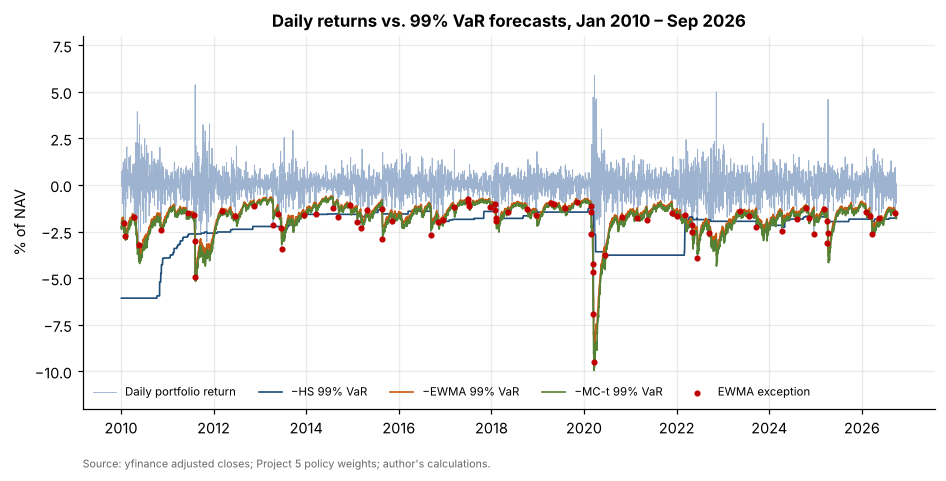

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.plot(B.index, B["ret"] * 100, color="#9DB3CF", lw=0.6, label="Daily portfolio return")
for i, m in enumerate(["HS", "EWMA", "MC-t"]):
    ax.plot(B.index, -B[f"{m} VaR99"] * 100, lw=1.1, color=PALETTE[[0, 1, 2][i]], label=f"−{m} 99% VaR")
h = hits_all[("EWMA", 99)]
ax.scatter(B.index[h.values], B["ret"][h.values] * 100, s=9, color="#C00000", zorder=4, label="EWMA exception")
ax.set_ylabel("% of NAV"); ax.set_ylim(-12, 8)
ax.set_title("Daily returns vs. 99% VaR forecasts, Jan 2010 – Sep 2026")
ax.legend(ncol=5, fontsize=7.5, loc="lower left")
source(ax, SRC)
fig.savefig(FIG / "fig_backtest.png"); plt.show()

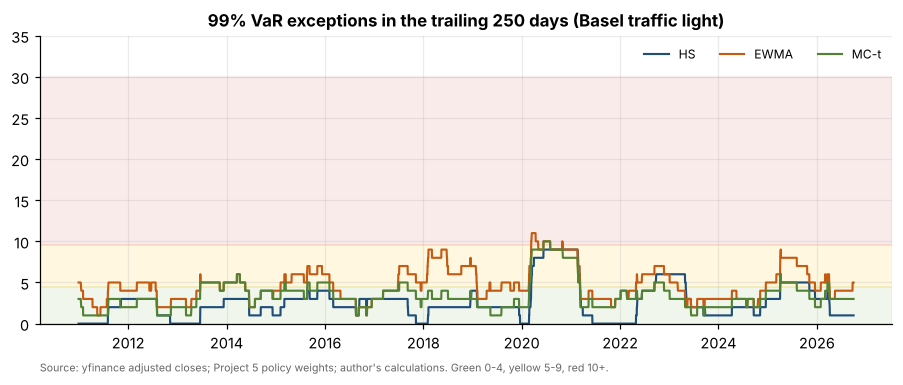

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.4))
for i, m in enumerate(["HS", "EWMA", "MC-t"]):
    ax.plot(hits_all[(m, 99)].astype(int).rolling(250).sum(), lw=1.4, label=m, color=PALETTE[i])
ax.axhspan(0, 4.5, color="#70AD47", alpha=0.10); ax.axhspan(4.5, 9.5, color="#FFC000", alpha=0.12)
ax.axhspan(9.5, 30, color="#C00000", alpha=0.08)
ax.set_ylim(0, max(12, BT["Max exceptions in 250d"].max() + 1))
ax.set_title("99% VaR exceptions in the trailing 250 days (Basel traffic light)")
ax.legend(ncol=3, fontsize=8)
source(ax, SRC + " Green 0-4, yellow 5-9, red 10+.")
fig.savefig(FIG / "fig_traffic_light.png"); plt.show()

## 4. Risk decomposition (EWMA covariance, 30 September 2026)

In [8]:
Cnow = C[R.index.get_loc(ASOF)]
# forecast for the day after ASOF: update with ASOF's return
x = R.loc[ASOF].values[:, None]
Cnext = 0.94 * Cnow + 0.06 * (x @ x.T)
comp, pct_vol, tot = risk.component_var(w, Cnext, 0.99)
DEC = pd.DataFrame({"Weight": w, "Component VaR99 (% NAV)": comp, "Component VaR99 ($m)": comp * NAV / 1e6,
                    "% of volatility": pct_vol,
                    "Stand-alone vol (ann.)": np.sqrt(np.diag(Cnext) * 252)}, index=R.columns)
DEC = DEC[DEC["Weight"] > 0]
print(f"EWMA 99% 1-day VaR for 1 October 2026: {tot:.4%} = ${tot * NAV / 1e6:.1f}m; portfolio vol (ann.) "
      f"{np.sqrt(w @ Cnext @ w * 252):.2%}")
DEC

EWMA 99% 1-day VaR for 1 October 2026: 1.5475% = $31.0m; portfolio vol (ann.) 10.56%


,Weight,Component VaR99 (% NAV),Component VaR99 ($m),% of volatility,Stand-alone vol (ann.)
EEM,0.19,0.004766,9.532952,0.308004,0.215396
TLT,0.15,0.002009,4.018962,0.129850,0.112804
HYG,0.16,0.000825,1.649307,0.053288,0.041036
VNQ,0.40,0.005450,10.900018,0.352173,0.115362
GLD,0.10,0.002425,4.849491,0.156684,0.251087


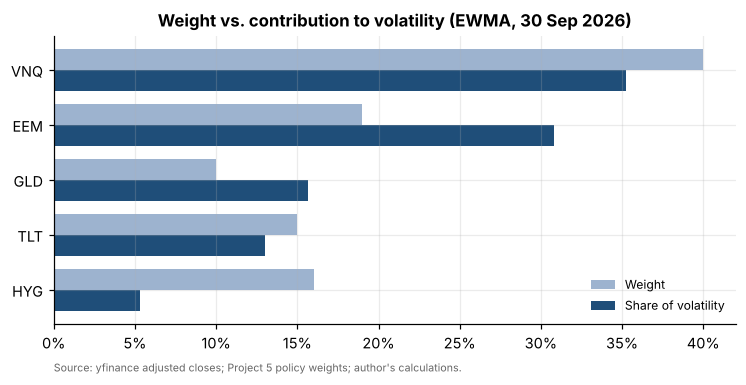

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.4))
d = DEC.sort_values("% of volatility")
ax.barh(d.index, d["Weight"], height=0.38, align="edge", color="#9DB3CF", label="Weight")
ax.barh(d.index, d["% of volatility"], height=-0.38, align="edge", color=PALETTE[0], label="Share of volatility")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Weight vs. contribution to volatility (EWMA, 30 Sep 2026)"); ax.legend(fontsize=8)
source(ax, SRC)
fig.savefig(FIG / "fig_decomposition.png"); plt.show()

## 5. Historical stress tests on today's weights (buy-and-hold over each window)

In [10]:
WINDOWS = {"Global financial crisis": ("2007-10-09", "2009-03-09"),
           "US downgrade and euro crisis": ("2011-07-22", "2011-10-03"),
           "COVID crash": ("2020-02-19", "2020-03-23"),
           "Inflation shock": ("2022-01-03", "2022-10-12")}
hist_rows = {}
for k, (a, b) in WINDOWS.items():
    a_, b_ = pd.Timestamp(a), pd.Timestamp(b)
    pa = px.loc[:a_].iloc[-1]          # close on (or before) the start date
    pb = px.loc[:b_].iloc[-1]
    etf_ret = pb / pa - 1
    port = float(etf_ret[W.index] @ W)
    hist_rows[k] = {"Start": a, "End": b, "Portfolio": port, "Loss $m": port * NAV / 1e6,
                    **{t: etf_ret[t] for t in W.index[W > 0]}, "SPY (reference)": etf_ret["SPY"]}
HS = pd.DataFrame(hist_rows).T
HS

,Start,End,Portfolio,Loss $m,EEM,TLT,HYG,VNQ,GLD,SPY (reference)
Global financial crisis,2007-10-09,2009-03-09,-0.380656,-761.312768,-0.591422,0.250745,-0.328689,-0.693059,0.239157,-0.551894
US downgrade and euro crisis,2011-07-22,2011-10-03,-0.110613,-221.225736,-0.278909,0.300505,-0.097782,-0.225377,0.031002,-0.178937
COVID crash,2020-02-19,2020-03-23,-0.241971,-483.942008,-0.307936,0.142343,-0.218962,-0.41541,-0.036168,-0.337173
Inflation shock,2022-01-03,2022-10-12,-0.257199,-514.397968,-0.290157,-0.293348,-0.145646,-0.318582,-0.073308,-0.244964


## 6. Hypothetical stress tests
Equity shocks apply to EEM and VNQ (the IPS classes REITs as equities). Bond ETFs are revalued with
effective duration and convexity from ishares.com; HYG's spread shock uses its effective duration as the
spread duration (iShares does not publish spread duration; for fixed-rate bonds the two are equal to
first order). Gold and commodity shocks are applied where specified; anything not specified is 0.

In [11]:
ish = pd.read_csv(DATA / "ishares_bond_characteristics.csv", index_col=0)
dur, cvx = ish["Effective duration (yrs)"].astype(float), ish["Convexity (/100)"].astype(float)
SCEN = {"Recession": {"eq": -0.30, "dy": -0.0100, "ds": 0.0250, "gold": 0.0, "cmdty": 0.0},
        "Stagflation": {"eq": -0.20, "dy": 0.0150, "ds": 0.0, "gold": 0.15, "cmdty": 0.25}}


def hypo(s):
    r = pd.Series(0.0, R.columns)
    for t in ["SPY", "EFA", "EEM", "VNQ"]:
        r[t] = s["eq"]
    for t in ["IEF", "TLT", "TIP"]:
        r[t] = risk.bond_return(dur[t], cvx[t], s["dy"])
    for t in ["LQD", "HYG"]:
        r[t] = risk.bond_return(dur[t], cvx[t], s["dy"], spread_dur=dur[t], ds=s["ds"])
    r["GLD"], r["DBC"] = s["gold"], s["cmdty"]
    return r


hyp_rows = {}
for k, s in SCEN.items():
    r = hypo(s)
    port = float(r[W.index] @ W)
    hyp_rows[k] = {"Portfolio": port, "Loss $m": port * NAV / 1e6, **{t: r[t] for t in W.index[W > 0]}}
HY = pd.DataFrame(hyp_rows).T
HY

,Portfolio,Loss $m,EEM,TLT,HYG,VNQ,GLD
Recession,-0.160624,-321.2480,-0.3,0.161600,-0.04915,-0.3,0.00
Stagflation,-0.138698,-277.3955,-0.2,-0.185025,-0.04965,-0.2,0.15


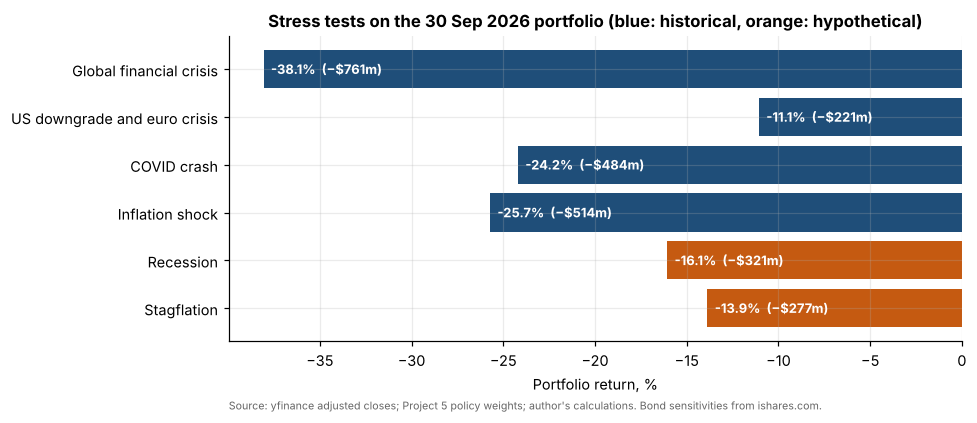

In [12]:
fig, ax = plt.subplots(figsize=(8.6, 3.6))
allst = pd.concat([HS["Portfolio"], HY["Portfolio"]]).astype(float)
cols = ["#1F4E79"] * len(HS) + ["#C55A11"] * len(HY)
ax.barh(allst.index[::-1], allst.values[::-1] * 100, color=cols[::-1])
for i, v in enumerate(allst.values[::-1]):
    ax.text(v * 100 + 0.4, i, f"{v:.1%}  (−${abs(v) * NAV / 1e6:,.0f}m)", va="center", ha="left", color="white", fontsize=8.5,
            weight="bold")
ax.set_xlabel("Portfolio return, %"); ax.set_title("Stress tests on the 30 Sep 2026 portfolio (blue: historical, orange: hypothetical)")
source(ax, SRC + " Bond sensitivities from ishares.com.")
fig.savefig(FIG / "fig_stress.png"); plt.show()

## Save

In [13]:
pd.DataFrame({"% of NAV": cur, "$m": cur * NAV / 1e6}).to_csv(DATA / "var_es_asof.csv")
ten.to_csv(DATA / "var_10day.csv")
BT.to_csv(DATA / "backtest_summary.csv")
DEC.to_csv(DATA / "risk_decomposition.csv")
HS.to_csv(DATA / "stress_historical.csv"); HY.to_csv(DATA / "stress_hypothetical.csv")
pd.DataFrame({k[0] + f" {k[1]}": v for k, v in hits_all.items()}).to_csv(DATA / "exceptions_daily.csv")
json.dump({"asof": str(ASOF.date()), "nav": NAV, "n_days": len(R), "bt_start": str(B.index[0].date()),
           "bt_days": len(B), "ewma_var99_next": float(tot), "ewma_vol_ann_next": float(np.sqrt(w @ Cnext @ w * 252)),
           "realised_vol_63d": float(p.iloc[-63:].std() * np.sqrt(252)),
           "realised_vol_full": float(p.std() * np.sqrt(252))},
          open(DATA / "meta.json", "w"), indent=2)